# Difference Map
This is a notebook to output difference maps from HGS output salinity data

I am using linear and t_hump for this right, and only the final time step

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from scipy.interpolate import griddata

#color lib
import cmocean

In [37]:
#load in data from sims, going to use lse_linear and lse_t_hump for now
#i am unsing the final frame (540 days)
df1 = pd.read_csv('../outputs/lse_linear/csv_outputs/salinity_step_0013.csv')
df2 = pd.read_csv('../outputs/lse_t_hump/csv_outputs/salinity_step_0013.csv')

In [38]:
print(df1)

          X    Y       Z  conc_pm.tds  (t = 540)
0     -20.0  0.0 -10.000                1.000000
1     -15.0  0.0 -10.000                0.996452
2     -10.0  0.0 -10.000                0.990399
3      -5.0  0.0 -10.000                0.981898
4       0.0  0.0 -10.000                0.970827
...     ...  ...     ...                     ...
1425  230.0  1.0   1.022                0.137663
1426  235.0  1.0   1.024                0.091177
1427  240.0  1.0   1.026                0.052378
1428  245.0  1.0   1.028                0.021830
1429  250.0  1.0   1.030                0.000000

[1430 rows x 4 columns]


In [39]:
diff = df2['conc_pm.tds  (t = 540)'] - df1['conc_pm.tds  (t = 540)']

In [40]:
diff_df = df1.copy()
diff_df['conc_pm.tds  (t = 540)'] = diff
diff_df = diff_df[['X', 'Z', 'conc_pm.tds  (t = 540)']]


In [41]:
diff_df

,X,Z,conc_pm.tds (t = 540)
0,-20.0,-10.000,0.000000
1,-15.0,-10.000,-0.000240
2,-10.0,-10.000,-0.001681
3,-5.0,-10.000,-0.003464
4,0.0,-10.000,-0.005271
...,...,...,...
1425,230.0,1.022,0.016339
1426,235.0,1.024,0.010631
1427,240.0,1.026,0.006192
1428,245.0,1.028,0.002593


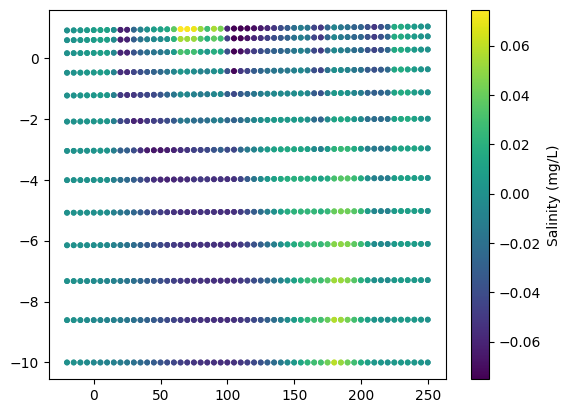

In [42]:
plt.scatter(diff_df['X'], diff_df['Z'], cmap = 'viridis', c = diff_df['conc_pm.tds  (t = 540)'], s = 10)
#plot color bar
plt.colorbar(label = 'Salinity (mg/L)')

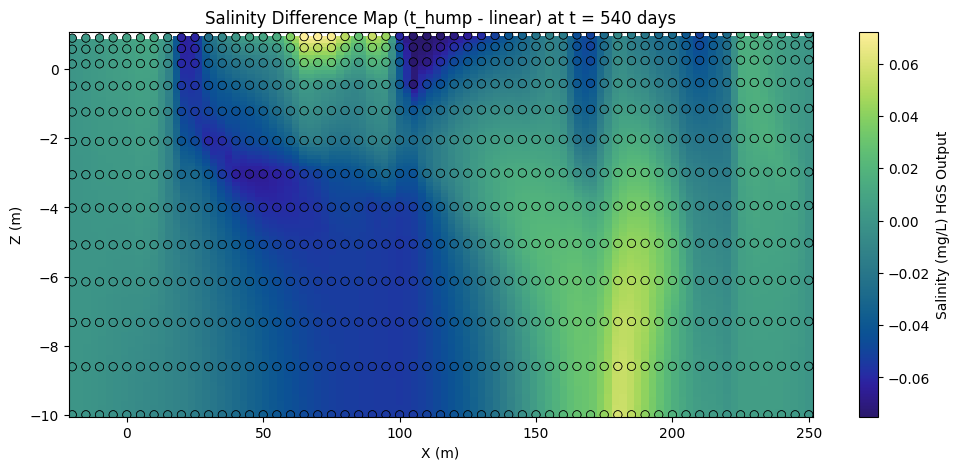

In [48]:
grid_lon, grid_lat = np.meshgrid(
    np.linspace(diff_df['X'].min(), diff_df['X'].max(), 100),
    np.linspace(diff_df['Z'].min(), diff_df['Z'].max(), 100),
)

grid_sal = griddata(
    points = (diff_df['X'], diff_df['Z']),
    values = diff_df['conc_pm.tds  (t = 540)'],
    xi = (grid_lon, grid_lat),
    method = 'linear',
)

fig, ax = plt.subplots(figsize = (12, 5))

mesh = ax.pcolormesh(
    grid_lon,
    grid_lat,
    grid_sal,
    cmap = cmocean.cm.haline,
    shading = 'auto'
)

#overalying original points on top of the mesh
ax.scatter(
    diff_df['X'],
    diff_df['Z'],
    c = diff_df['conc_pm.tds  (t = 540)'],
    cmap = cmocean.cm.haline,
    edgecolor = 'k',
    linewidth = 0.5,
    s = 35,
    norm = mesh.norm,
    label = 'Salinity (mg/L) HGS Output'
)

cbar = fig.colorbar(mesh, ax = ax)
cbar.set_label('Salinity (mg/L) HGS Output')
ax.set_xlabel('X (m)')
ax.set_ylabel('Z (m)')
ax.set_title('Salinity Difference Map (t_hump - linear) at t = 540 days')
#ax.legend(loc = 'upper right')

plt.show()